# Pulmonary Risk from Scoliosis X-rays — 3-Class Ensemble (the ≥0.85 push)

Strategy (explained step by step in chat):
1. **3 clinical classes** — `healthy / mild (1°+2°) / significant (3°)` — absorbs the
   ambiguous 1↔2 boundary that caps the 4-class model at ~76%.
2. **5-fold ensemble** — 5 models trained on different folds of train+valid, their
   probabilities averaged on the untouched official test set.
3. **TTA + expected-severity decoding** — 4 augmented views per image, probability-
   weighted decision instead of raw argmax.
4. Full report: 3-class accuracy, per-class F1, screening sensitivity/specificity,
   pulmonary risk scores, per-image CSV, saved models — all under
   `outputs_3class_ensemble/` (your other runs are not touched).

> ⚠️ Research screening aid — not a diagnostic device. Validate against spirometry
> and clinical review before any real-world use.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r "/content/drive/MyDrive/data" /content/data
!ls data        # must print: test  train  valid

Mounted at /content/drive
test  train  valid


In [ ]:
# @title Configuration
from pathlib import Path

DATA_DIR   = Path("data")                 # data/train|valid|test/<4 class folders>
OUTPUT_DIR = Path("outputs_3class_ensemble"); OUTPUT_DIR.mkdir(exist_ok=True)

BACKBONE     = "efficientnet_b0"          # "resnet18" or "efficientnet_b0"
IMG_WIDTH    = 512                        # contour-pipeline working width
IMG_SIZE     = 448
BATCH_SIZE   = 12                         # lower to 8 if CUDA OOM
NUM_WORKERS  = 0
EPOCHS       = 25                         # per fold (early stopping still applies)
LR           = 2.5e-4
PATIENCE     = 8
K_FOLDS      = 5                          # ensemble size
USE_SPINE_CROP   = True
BALANCE_CLASSES  = True
LABEL_SMOOTH      = 0.05
HEAD_LR_MULT      = 10
SEED = 42

CLASS_ORDER = ["healthy", "mild", "significant"]          # the 3-class scheme
CLASS_MAP = {                                             # original folder -> 3-class
    "healthy": "healthy",
    "1-degree": "mild", "2-degree": "mild",
    "3-degree": "significant",
}
# pulmonary-risk weights per 3-class label (calibrate on spirometry when available)
RISK_WEIGHTS = {"healthy": 0.00, "mild": 0.40, "significant": 0.85}
RISK_BANDS = [(0.20, "LOW"), (0.50, "MODERATE"), (1.01, "HIGH")]

In [ ]:
# @title Imports
import warnings, random, copy, gc
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
    import torchvision
except ImportError as e:
    raise ImportError("PyTorch is required:  pip install torch torchvision") from e

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

device: cuda | torch 2.11.0+cu128 | torchvision 0.26.0+cu128


## Step 1 — Reused contour pipeline
Same detection stack as before: body contour, DP ridge-traced spine contour,
geometric features. Feeds the hybrid head + the spine-crop + the overlays.

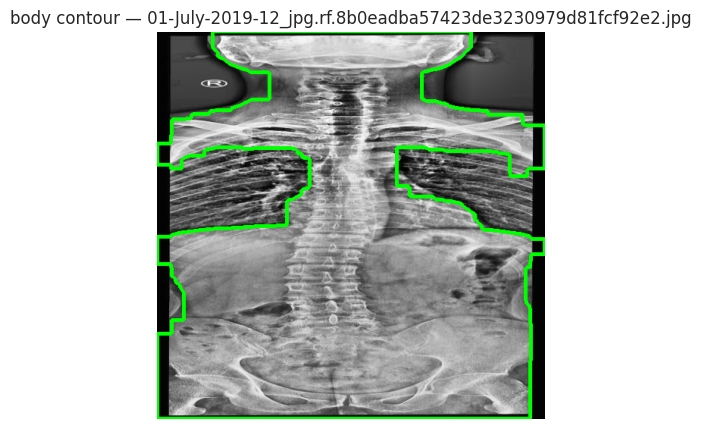

In [ ]:
# @title Preprocessing + body-contour segmentation
def preprocess(path, img_width=IMG_WIDTH):
    """Load an X-ray JPG, fix polarity, resize, enhance local contrast."""
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise IOError(f"could not read {path}")
    h, w = img.shape
    scale = img_width / w
    img = cv2.resize(img, (img_width, int(h * scale)), interpolation=cv2.INTER_AREA)
    # polarity: bone must be BRIGHTER than air/background. If the borders are
    # brighter than the centre, the radiograph is inverted -> flip it.
    border = np.concatenate([img[:, :30].ravel(), img[:, -30:].ravel()])
    centre = img[:, img.shape[1] // 3 : 2 * img.shape[1] // 3].ravel()
    if np.mean(border) > np.mean(centre):
        img = 255 - img
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    return clahe.apply(img)


def body_mask(img):
    """Background-offset threshold + largest central component + hole filling.

    Robust on real radiographs whose background is grey gradient, not black."""
    blur = cv2.GaussianBlur(img, (7, 7), 0)
    border = np.concatenate([blur[:, :25].ravel(), blur[:, -25:].ravel(),
                             blur[:25].ravel(), blur[-25:].ravel()])
    bg = float(np.median(border))
    thr = bg + 0.20 * (np.percentile(blur, 95) - bg)
    _, th = cv2.threshold(blur, thr, 255, cv2.THRESH_BINARY)
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN, np.ones((15, 15), np.uint8))
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((35, 35), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(th)
    if n <= 1:
        return None, None
    big_i = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    mask = np.where(lab == big_i, 255, 0).astype(np.uint8)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    big = max(cnts, key=cv2.contourArea)
    mask = np.zeros_like(mask)
    cv2.drawContours(mask, [big], -1, 255, -1)      # also fills holes
    return mask, big


# quick sanity check on one image
_sample = sorted(DATA_DIR.rglob("*.jpg"))
if _sample:
    _img = preprocess(_sample[0])
    _mask, _cnt = body_mask(_img)
    _vis = cv2.cvtColor(_img, cv2.COLOR_GRAY2BGR)
    if _cnt is not None:
        cv2.drawContours(_vis, [_cnt], -1, (0, 255, 0), 3)
    plt.figure(figsize=(5, 9))
    plt.imshow(_vis)
    plt.title(f"body contour — {_sample[0].name}")
    plt.axis("off")
    plt.show()
else:
    print(f"no JPGs found under {DATA_DIR} — add images first")

In [ ]:
# @title Spine contour tracing (DP ridge path)
def _dp_ridge_path(evidence, y0, y1, xL, xR, max_slope=2, lam=0.02):
    """Dynamic-programming maximal-evidence vertical path with a smoothness
    (turn) penalty, so the path prefers straight, spine-like contours and is
    not stolen by diagonal ribs."""
    E = evidence[y0:y1, xL:xR].astype(np.float32)
    nR, nC = E.shape
    S = int(max_slope)
    NEG = np.float32(-1e18)
    cost = E[0].copy()
    parents = np.zeros((nR, nC), np.int16)
    moves = np.arange(-S, S + 1)
    move_pen = lam * np.abs(moves).astype(np.float32)
    for y in range(1, nR):
        P = np.full(nC + 2 * S, NEG, np.float32)
        P[S : S + nC] = cost
        win = np.stack([P[S + s : S + s + nC] for s in moves])
        best_idx = win.argmax(axis=0)
        best = win[best_idx, np.arange(nC)] - move_pen[best_idx]
        parents[y] = best_idx - S
        cost = E[y] + best
        del win
    path = np.zeros(nR, np.int32)
    path[-1] = int(cost.argmax())
    for y in range(nR - 2, -1, -1):
        path[y] = path[y + 1] + parents[y + 1, path[y + 1]]
    return path + xL


def spine_centerline(img, mask, min_pts=25):
    """Trace the spine contour (v2, tuned on real radiographs).

    Evidence = horizontal top-hat x brightness x vertical-elongation, times a
    midline prior (the spine lives near the body midline); path = DP ridge with
    turn penalty. Returns (centerline Nx2 [x,y], raw_pts, body_width)."""
    idx = np.arange(img.shape[0])
    M = cv2.moments(mask)
    if M["m00"] == 0:
        return None, None, None
    width_vec = mask.sum(axis=1) / 255.0                    # per-row body width
    ys_body = idx[width_vec > 0]
    if len(ys_body) < 40:
        return None, None, None
    body_width = float(np.median(width_vec[ys_body]))
    y0, y1 = int(ys_body[0]), int(ys_body[-1])
    cx = float(np.where(mask.max(axis=0) > 0)[0].mean())    # body midline

    kw = max(int(0.14 * body_width) | 1, 25)                # horizontal opening
    kh = max(int(0.10 * body_width) | 1, 21)                # vertical opening
    Vh = cv2.subtract(img, cv2.morphologyEx(
        img, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (kw, 1))))
    Vv = cv2.subtract(img, cv2.morphologyEx(
        img, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, kh))))
    Vh = cv2.GaussianBlur(Vh, (5, 5), 0).astype(np.float32)
    Vv = cv2.GaussianBlur(Vv, (5, 5), 0).astype(np.float32)
    elong = Vh / (Vh + Vv + 10.0)                           # ~1 vertical ridge, ~0 horizontal
    evidence = (Vh / 255.0) * (img.astype(np.float32) / 255.0) * elong * elong
    evidence[mask == 0] = 0                                 # stay inside the body
    xs_all = np.arange(img.shape[1])
    prior = np.exp(-0.5 * ((xs_all - cx) / (0.20 * body_width)) ** 2).astype(np.float32)
    evidence *= prior[None, :]                              # midline prior

    col_any = np.where(mask.max(axis=0) > 0)[0]
    half = max(0.35 * body_width, 40)
    xL = int(max(cx - half, col_any[0]))
    xR = int(min(cx + half, col_any[-1] + 1))

    r0 = y0 + int(0.05 * (y1 - y0))                         # skip top-of-head rows
    xs_path = _dp_ridge_path(evidence, r0, y1, xL, xR, max_slope=2, lam=0.02)
    ys_path = np.arange(r0, y1)

    # trim rows where the body is narrow (head / neck / extremities)
    med_w = np.median(width_vec[ys_body])
    sel = np.where((width_vec >= 0.50 * med_w)[ys_path])[0]
    if len(sel) < min_pts:
        return None, None, None
    xs_path, ys_path = xs_path[sel[0] : sel[-1] + 1], ys_path[sel[0] : sel[-1] + 1]

    raw = np.stack([xs_path, ys_path.astype(float)], axis=1)
    win = max(int(0.04 * len(xs_path)) | 1, 9)              # edge-padded smoothing
    xs_pad = np.pad(xs_path.astype(float), win // 2, mode="edge")
    xs_s = np.convolve(xs_pad, np.ones(win) / win, mode="valid")[: len(xs_path)]
    return np.stack([xs_s, ys_path.astype(float)], axis=1), raw, body_width

In [ ]:
# @title Feature extraction
def contour_features(img, mask, centerline, body_width):
    """Geometric features from the detected spine contour + chest asymmetry."""
    H, W = img.shape
    xs, ys = centerline[:, 0], centerline[:, 1]
    # 1. Cobb-like angle: angular span between most-tilted tangents
    dx = np.gradient(xs, ys)
    theta = np.degrees(np.arctan(dx))                # 0 deg = perfectly vertical
    cobb_like = float(theta.max() - theta.min())
    # 2. max lateral deviation from the straight chord (normalised)
    dev = xs - (xs[0] + (xs[-1] - xs[0]) * (ys - ys[0]) / (ys[-1] - ys[0] + 1e-9))
    max_dev = float(np.abs(dev).max() / max(body_width, 1))
    # 3. total curvature (bending-energy proxy)
    d2 = np.gradient(dx, ys)
    bend = float(np.trapezoid(np.abs(d2), ys) / max(ys[-1] - ys[0], 1))
    # 4. apex position along the spine (0=top/cervical, 1=bottom/lumbar)
    apex_t = float((ys[int(np.argmax(np.abs(dev)))] - ys[0]) / (ys[-1] - ys[0] + 1e-9))
    # 5. direction of the main curve
    direction = float(np.sign(dev[int(np.argmax(np.abs(dev)))]))
    # 6. chest (thoracic) left/right asymmetry of the body contour
    idx = np.arange(H)
    ys_body = idx[mask.max(axis=1) > 0]
    y0 = int(ys_body[0])
    chest = mask[y0 : int(y0 + 0.35 * (ys_body[-1] - ys_body[0]))]
    col_has = chest.max(axis=0) > 0
    mid = int((xs[0] + xs[-1]) / 2)
    left, right = col_has[:mid].sum(), col_has[mid:].sum()
    asym = float(abs(left - right) / max(left + right, 1))
    # 7. regional tilts
    upper, lower = theta[ys < np.median(ys)], theta[ys >= np.median(ys)]
    return {
        "cobb_like_angle": cobb_like,
        "max_lateral_dev": max_dev,
        "bending_energy": bend,
        "apex_position": apex_t,
        "curve_direction": direction,
        "chest_asymmetry": asym,
        "upper_tilt": float(np.abs(upper - np.median(theta)).max()),
        "lower_tilt": float(np.abs(lower - np.median(theta)).max()),
    }


def extract_features(path, verbose=False):
    """Full pipeline for one image -> (features dict, img, mask, overlay_data)."""
    img = preprocess(path)
    mask, _ = body_mask(img)
    if mask is None:
        return None, img, None, None
    cl, raw, bw = spine_centerline(img, mask)
    if cl is None:
        return None, img, mask, None
    feats = contour_features(img, mask, cl, bw)
    if verbose:
        print(path, feats)
    return feats, img, mask, (cl, raw, bw)


def show_overlay(path, ax=None):
    """Draw body contour (green), DP spine contour (blue), raw trace (red), apex (yellow)."""
    img = preprocess(path)
    mask, big = body_mask(img)
    cl, raw, bw = spine_centerline(img, mask)
    vis = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    if big is not None:
        cv2.drawContours(vis, [big], -1, (0, 255, 0), 2)
    if cl is not None:
        xs, ys = cl[:, 0], cl[:, 1]
        dev = xs - (xs[0] + (xs[-1] - xs[0]) * (ys - ys[0]) / (ys[-1] - ys[0] + 1e-9))
        apex = int(np.argmax(np.abs(dev)))
        for x, y in raw.astype(int)[::4]:
            cv2.circle(vis, (x, y), 1, (0, 0, 255), -1)
        cv2.polylines(vis, [cl.astype(np.int32).reshape(-1, 1, 2)], False, (255, 0, 0), 2)
        cv2.circle(vis, (int(xs[apex]), int(ys[apex])), 7, (0, 255, 255), 2)
    solo = ax is None
    if solo:
        fig, ax = plt.subplots(figsize=(4.5, 8))
    ax.imshow(vis)
    ax.set_title(Path(path).name, fontsize=9)
    ax.axis("off")
    return ax


print("feature functions ready")

feature functions ready


## Step 2 — Dataset assembly with 3-class labels

Images keep their **original folder label** (`1-degree` etc.) for reference, and get a
mapped 3-class label `healthy / mild / significant` used for training and reporting.
The spine crop box from the detected contour is stored for the CNN branch.

In [ ]:
# @title Scan + contour features + 3-class mapping
FEATURES = ["cobb_like_angle", "max_lateral_dev", "bending_energy", "apex_position",
            "curve_direction", "chest_asymmetry", "upper_tilt", "lower_tilt"]

OFFICIAL_SPLITS = all((DATA_DIR / s).is_dir() for s in ["train", "valid", "test"])
print("layout:", "OFFICIAL train/valid/test folders" if OFFICIAL_SPLITS else "flat class folders")

files, labels4, splits = [], [], []
if OFFICIAL_SPLITS:
    for sp in ["train", "valid", "test"]:
        for cls in CLASS_MAP:
            for p in sorted((DATA_DIR / sp / cls).rglob("*.jpg")):
                files.append(p); labels4.append(cls); splits.append(sp)
else:
    for cls in CLASS_MAP:
        for p in sorted(DATA_DIR.rglob("*.jpg")):
            if cls in p.parts:
                files.append(p); labels4.append(cls); splits.append("all")
assert files, f"no JPGs found under {DATA_DIR}"

rows = []
for p, lab4, sp in tqdm(list(zip(files, labels4, splits)), desc="contour features"):
    try:
        f, _img, _mask, _ov = extract_features(p)
    except Exception:
        f, _ov = None, None
    row = {"file": str(p), "label": lab4, "label3": CLASS_MAP[lab4], "split": sp,
           "spine_detected": int(f is not None)}
    for k in FEATURES:
        row[k] = float(f[k]) if f else 0.0
    box = [np.nan] * 4
    if _ov is not None and _ov[0] is not None:
        cl, _raw, bw = _ov
        m = 0.55 * bw
        span = cl[:, 1].max() - cl[:, 1].min()
        box = [max(cl[:, 0].min() - m, 0), cl[:, 0].max() + m + 1,
               max(cl[:, 1].min() - 0.04 * span, 0), cl[:, 1].max() + 0.04 * span + 1]
    row["crop_x0"], row["crop_x1"], row["crop_y0"], row["crop_y1"] = box
    rows.append(row)

df = pd.DataFrame(rows)
df["y_idx"] = df["label3"].map({c: i for i, c in enumerate(CLASS_ORDER)})

print(f"\n{len(df)} images | spine detected: {df.spine_detected.sum()}")
print("\n3-class distribution:")
print(pd.crosstab(df["label3"], df["split"]).reindex(CLASS_ORDER))
if OFFICIAL_SPLITS:
    print("\noriginal grades inside each 3-class label:")
    print(pd.crosstab(df["label3"], df["label"]).reindex(CLASS_ORDER))

layout: OFFICIAL train/valid/test folders


contour features:   0%|          | 0/3199 [00:00<?, ?it/s]


3199 images | spine detected: 3196

3-class distribution:
split        test  train  valid
label3                         
healthy        54    414    132
mild          201   1101    297
significant    83    736    181

original grades inside each 3-class label:
label        1-degree  2-degree  3-degree  healthy
label3                                            
healthy             0         0         0      600
mild              599      1000         0        0
significant         0         0      1000        0


In [ ]:
# @title Frames + feature scaler (fit on all NON-test images)
trva_df = df[df["split"] != "test"].reset_index(drop=True) if OFFICIAL_SPLITS else df.copy()
te_df   = (df[df["split"] == "test"].reset_index(drop=True) if OFFICIAL_SPLITS
           else df.iloc[:0].copy())          # empty -> fallback below

if len(te_df) < 10:                           # no usable official test split
    from sklearn.model_selection import train_test_split
    trva_df, te_df = train_test_split(df, test_size=0.15, stratify=df["label3"],
                                      random_state=SEED)
    trva_df, te_df = trva_df.reset_index(drop=True), te_df.reset_index(drop=True)
    print("WARNING: using a random 15% test split (official test folder too small)")

if trva_df["spine_detected"].sum() >= 2:
    scaler = StandardScaler().fit(trva_df.loc[trva_df.spine_detected == 1, FEATURES].to_numpy(np.float64))
else:
    scaler = StandardScaler().fit(np.zeros((2, len(FEATURES))))
print(f"ensemble pool (train+valid): {len(trva_df)} | test: {len(te_df)}")

ensemble pool (train+valid): 2861 | test: 338


## Step 3 — Image pipeline & model (shared with the 4-class notebook)

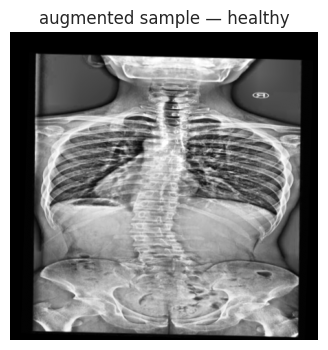

In [ ]:
# @title Dataset with letterbox + augmentation
MEAN, STD = 0.485, 0.229                       # ImageNet grayscale approx.

def letterbox_square(gray, size):
    """Preserve aspect ratio, pad with black (== X-ray air background)."""
    h, w = gray.shape
    s = size / max(h, w)
    img = cv2.resize(gray, (max(1, int(w * s)), max(1, int(h * s))), interpolation=cv2.INTER_AREA)
    canvas = np.zeros((size, size), np.float32)
    y0, x0 = (size - img.shape[0]) // 2, (size - img.shape[1]) // 2
    canvas[y0:y0 + img.shape[0], x0:x0 + img.shape[1]] = img.astype(np.float32) / 255.0
    return canvas

def augment(x):
    """Random affine + photometric jitter on a float [0,1] image."""
    h, w = x.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), random.uniform(-6, 6), random.uniform(0.92, 1.08))
    M[:, 2] += np.random.uniform(-0.04, 0.04, 2) * w
    x = cv2.warpAffine(x, M, (w, h), borderValue=0.0)
    if random.random() < 0.5:
        x = x[:, ::-1]
    x = np.clip(x, 0, 1) ** random.uniform(0.8, 1.25)                       # gamma
    x = np.clip((x - 0.5) * random.uniform(0.9, 1.1) + 0.5 + random.uniform(-0.05, 0.05), 0, 1)
    if random.random() < 0.5:
        noise = np.random.normal(0, random.uniform(0.01, 0.03), x.shape).astype(np.float32)
        x = np.clip(x + noise, 0, 1)
    return np.ascontiguousarray(x, dtype=np.float32)

N_EXTRA = len(FEATURES) + 1                     # features + spine_detected flag

class SpineDataset(Dataset):
    def __init__(self, frame, scaler, train=False):
        self.frame = frame.reset_index(drop=True)
        self.scaler, self.train = scaler, train

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        r = self.frame.iloc[i]
        x = prep_image(r)
        if self.train:
            x = augment(x)
        t = torch.from_numpy(x).unsqueeze(0)
        t = ((t - MEAN) / STD).repeat(3, 1, 1)                     # 3-channel
        extra = np.zeros(N_EXTRA, np.float32)
        if r["spine_detected"] == 1:
            extra[: len(FEATURES)] = self.scaler.transform(
                r[FEATURES].to_numpy(np.float64).reshape(1, -1)).ravel()
        extra[-1] = float(r["spine_detected"])
        return t, torch.from_numpy(extra), int(r["y_idx"])

def prep_image(r):
    """preprocess -> optional spine crop -> letterbox. Used by dataset, TTA and Grad-CAM."""
    gray = preprocess(r["file"])
    if USE_SPINE_CROP and "crop_x0" in r and not pd.isna(r["crop_x0"]):
        gray = gray[int(r["crop_y0"]):int(r["crop_y1"]), int(r["crop_x0"]):int(r["crop_x1"])]
    return letterbox_square(gray, IMG_SIZE)

def make_loader(frame, scaler, train, shuffle=False):
    ds = SpineDataset(frame, scaler, train=train)
    sampler = None
    if train and BALANCE_CLASSES:
        counts = frame["y_idx"].value_counts()
        w = frame["y_idx"].map(lambda c: 1.0 / counts[c]).to_numpy(np.float64)
        sampler = WeightedRandomSampler(w, num_samples=len(frame), replacement=True)
        shuffle = False                     # sampler already randomises
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

# visual check of one augmented training sample
_x, _e, _y = SpineDataset(trva_df, scaler, train=True)[0]
plt.figure(figsize=(4, 4))
plt.imshow(_x[0], cmap="gray"); plt.title(f"augmented sample — {CLASS_ORDER[_y]}"); plt.axis("off")
plt.show()

In [ ]:
# @title Hybrid ResNet-18
def _make_backbone(name):
    """ImageNet backbone factory -> (module, feature_dim)."""
    from torchvision.models import (resnet18, ResNet18_Weights,
                                    efficientnet_b0, EfficientNet_B0_Weights)
    if name == "efficientnet_b0":
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        n_feat = m.classifier[1].in_features
        m.classifier = nn.Identity()
        return m, n_feat
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    n_feat = m.fc.in_features
    m.fc = nn.Identity()
    return m, n_feat


class ScoliosisNet(nn.Module):
    """CNN backbone (+ optional contour-feature MLP) -> severity logits."""
    def __init__(self, n_classes, n_extra=0, dropout=0.3, backbone=BACKBONE):
        super().__init__()
        self.backbone, n_feat = _make_backbone(backbone)
        self.extra_mlp = (nn.Sequential(nn.Linear(n_extra, 32), nn.ReLU(), nn.Dropout(0.2))
                          if n_extra else None)
        d = n_feat + (32 if n_extra else 0)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(d, n_classes))

    def forward(self, img, extra=None):
        z = self.backbone(img)
        if self.extra_mlp is not None and extra is not None:
            z = torch.cat([z, self.extra_mlp(extra)], dim=1)
        return self.head(z)

print("model class ready")

model class ready


## Step 4 — Fold training
Each fold trains a fresh model on 4/5 of the pool and validates on the held-out
fold — early stopping on fold-validation macro-F1 keeps overfitting in check.
`train_model` receives the shared scaler so all folds and the test set are
encoded consistently.

In [ ]:
# @title Train / predict helpers (3-class)
def predict_probs_ens(model, frame, scaler, train=False):
    """Softmax probabilities for a frame with one model."""
    model.eval()
    loader = make_loader(frame, scaler, train=train)
    ps, ys = [], []
    with torch.no_grad():
        for img, extra, y in loader:
            out = model(img.to(device), extra.to(device))
            ps.append(torch.softmax(out, 1).cpu()); ys.append(y.cpu())
    return torch.cat(ps).numpy(), torch.cat(ys).numpy()


def train_model(tr_frame, va_frame, scaler, n_epochs=EPOCHS, patience=PATIENCE, verbose=True):
    """Train one fold model; early-stop on validation macro-F1."""
    set_seed(SEED)
    cw = compute_class_weight("balanced", classes=np.arange(len(CLASS_ORDER)),
                              y=tr_frame["y_idx"])
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32).to(device),
                                    label_smoothing=LABEL_SMOOTH)

    model = ScoliosisNet(len(CLASS_ORDER), n_extra=N_EXTRA).to(device)
    head_params = list(model.head.parameters()) + (
        list(model.extra_mlp.parameters()) if model.extra_mlp is not None else [])
    opt = torch.optim.AdamW([
        {"params": list(model.backbone.parameters()), "lr": LR},
        {"params": head_params, "lr": LR * HEAD_LR_MULT},
    ], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)

    best_f1, best_state, bad = -1.0, None, 0
    for ep in range(1, n_epochs + 1):
        model.train()
        for img, extra, y in make_loader(tr_frame, scaler, train=True, shuffle=True):
            img, extra, y = img.to(device), extra.to(device), y.to(device)
            opt.zero_grad()
            loss = criterion(model(img, extra), y)
            loss.backward(); opt.step()
        sched.step()

        probs, ys = predict_probs_ens(model, va_frame, scaler)
        f1 = f1_score(ys, probs.argmax(1), average="macro", zero_division=0)
        if verbose:
            print(f"  ep {ep:02d} | val acc {(probs.argmax(1)==ys).mean():.3f} macroF1 {f1:.3f}")
        if f1 > best_f1 + 1e-4:
            best_f1, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                if verbose: print(f"  early stop @ ep {ep} (best macroF1 {best_f1:.3f})")
                break
    model.load_state_dict(best_state)
    return model

In [ ]:
# @title Train the K-fold ensemble
skf = StratifiedKFold(K_FOLDS, shuffle=True, random_state=SEED)
fold_models, fold_accs = [], []

for k, (a, b) in enumerate(skf.split(trva_df, trva_df["y_idx"]), 1):
    print(f"=== fold {k}/{K_FOLDS} ===")
    m_k = train_model(trva_df.iloc[a], trva_df.iloc[b], scaler, verbose=(k == 1))
    p_k, y_k = predict_probs_ens(m_k, trva_df.iloc[b], scaler)
    fold_accs.append((p_k.argmax(1) == y_k).mean())
    print(f"fold {k} holdout accuracy: {fold_accs[-1]:.3f}")
    fold_models.append(m_k)
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

print(f"\nfold accuracies: {np.round(fold_accs, 3)}  mean {np.mean(fold_accs):.3f} ± {np.std(fold_accs):.3f}")
print("cross-validated accuracy (honest estimate):", round(np.mean(fold_accs), 3))

=== fold 1/5 ===
  ep 01 | val acc 0.724 macroF1 0.721
  ep 02 | val acc 0.743 macroF1 0.741
  ep 03 | val acc 0.763 macroF1 0.762
  ep 04 | val acc 0.707 macroF1 0.706
  ep 05 | val acc 0.738 macroF1 0.738
  ep 06 | val acc 0.782 macroF1 0.779
  ep 07 | val acc 0.782 macroF1 0.780
  ep 08 | val acc 0.742 macroF1 0.741
  ep 09 | val acc 0.798 macroF1 0.794
  ep 10 | val acc 0.806 macroF1 0.798
  ep 11 | val acc 0.812 macroF1 0.807
  ep 12 | val acc 0.775 macroF1 0.772
  ep 13 | val acc 0.785 macroF1 0.779
  ep 14 | val acc 0.785 macroF1 0.781
  ep 15 | val acc 0.784 macroF1 0.782
  ep 16 | val acc 0.773 macroF1 0.771
  ep 17 | val acc 0.792 macroF1 0.791
  ep 18 | val acc 0.799 macroF1 0.797
  ep 19 | val acc 0.806 macroF1 0.803
  early stop @ ep 19 (best macroF1 0.807)
fold 1 holdout accuracy: 0.812
=== fold 2/5 ===
fold 2 holdout accuracy: 0.864
=== fold 3/5 ===
fold 3 holdout accuracy: 0.827
=== fold 4/5 ===
fold 4 holdout accuracy: 0.851
=== fold 5/5 ===
fold 5 holdout accuracy: 0.

## Step 5 — Official test-set report (5-model committee vote)

The test folder was never touched during training. Each of the 5 models votes;
probabilities are averaged; then the smarter decoding is applied.

3-CLASS TEST ACCURACY (5-fold ensemble): 0.867   macro-F1: 0.857

              precision    recall  f1-score   support

     healthy       0.74      0.94      0.83        54
        mild       0.93      0.84      0.88       201
 significant       0.83      0.89      0.86        83

    accuracy                           0.87       338
   macro avg       0.83      0.89      0.86       338
weighted avg       0.88      0.87      0.87       338



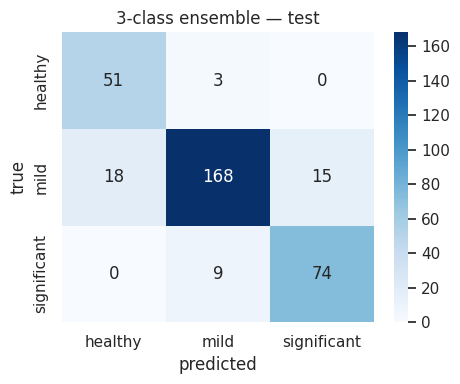

original grade vs predicted 3-class:
pred3     healthy  mild  significant
label                               
1-degree       15    40            1
2-degree        3   128           14
3-degree        0     9           74
healthy        51     3            0


In [ ]:
# @title Ensemble test predictions + 3-class report
def ensemble_probs(frame, models, scaler):
    P = None
    for m in models:
        p, _ = predict_probs_ens(m, frame, scaler)
        P = p if P is None else P + p
    return P / len(models)

ens_probs = ensemble_probs(te_df, fold_models, scaler)
ens_pred = ens_probs.argmax(1)
ens_ys = te_df["y_idx"].to_numpy()

acc = (ens_pred == ens_ys).mean()
print(f"3-CLASS TEST ACCURACY (5-fold ensemble): {acc:.3f}   macro-F1: "
      f"{f1_score(ens_ys, ens_pred, average='macro', zero_division=0):.3f}\n")
print(classification_report(ens_ys, ens_pred, target_names=CLASS_ORDER, zero_division=0))

cm = confusion_matrix(ens_ys, ens_pred, labels=range(len(CLASS_ORDER)))
plt.figure(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("3-class ensemble — test")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "ensemble_confusion_matrix.png", bbox_inches="tight")
plt.show()

# how do the original 4 grades land inside the 3 classes?
te_df_out = te_df.copy(); te_df_out["pred3"] = [CLASS_ORDER[i] for i in ens_pred]
print("original grade vs predicted 3-class:")
print(pd.crosstab(te_df_out["label"], te_df_out["pred3"]).reindex(columns=CLASS_ORDER))

screening accuracy : 0.938
sensitivity (scoliosis caught) : 0.937
specificity (healthy cleared)  : 0.944


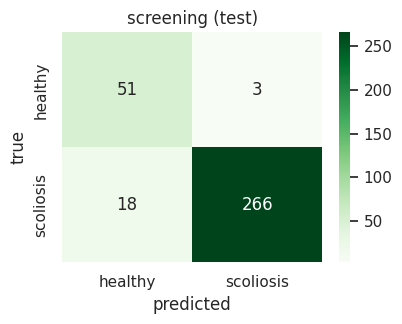

In [ ]:
# @title Screening view: healthy vs any-scoliosis
y_bin = (ens_ys != CLASS_ORDER.index("healthy")).astype(int)
p_bin = (ens_pred != CLASS_ORDER.index("healthy")).astype(int)
sens, spec = recall_score(y_bin, p_bin), recall_score(1 - y_bin, 1 - p_bin)
print(f"screening accuracy : {(y_bin == p_bin).mean():.3f}")
print(f"sensitivity (scoliosis caught) : {sens:.3f}")
print(f"specificity (healthy cleared)  : {spec:.3f}")

cm_b = confusion_matrix(y_bin, p_bin)
plt.figure(figsize=(4.2, 3.4))
sns.heatmap(cm_b, annot=True, fmt="d", cmap="Greens",
            xticklabels=["healthy", "scoliosis"], yticklabels=["healthy", "scoliosis"])
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("screening (test)")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "ensemble_screening.png", bbox_inches="tight")
plt.show()

In [ ]:
# @title TTA + expected-severity decoding (final numbers)
def predict_probs_tta_one(model, frame, scaler):
    """Average softmax over flip + two small rotations for one model."""
    model.eval()
    out_probs = []
    for i in range(len(frame)):
        r = frame.iloc[i]
        base = prep_image(r)
        extra = np.zeros(N_EXTRA, np.float32)
        if r["spine_detected"] == 1:
            extra[: len(FEATURES)] = scaler.transform(
                r[FEATURES].to_numpy(np.float64).reshape(1, -1)).ravel()
        extra[-1] = float(r["spine_detected"])
        extra_t = torch.from_numpy(extra).unsqueeze(0)
        h, w = base.shape
        Mp = cv2.getRotationMatrix2D((w / 2, h / 2), 4, 1.0)
        Mn = cv2.getRotationMatrix2D((w / 2, h / 2), -4, 1.0)
        variants = [base, base[:, ::-1].copy(),
                    cv2.warpAffine(base, Mp, (w, h), borderValue=0.0),
                    cv2.warpAffine(base, Mn, (w, h), borderValue=0.0)]
        probs = np.zeros(len(CLASS_ORDER), np.float64)
        with torch.no_grad():
            for v in variants:
                t = torch.from_numpy(np.ascontiguousarray(v, dtype=np.float32)).unsqueeze(0)
                t = ((t - MEAN) / STD).repeat(3, 1, 1).unsqueeze(0).to(device)
                out = model(t, extra_t.to(device))
                probs += torch.softmax(out, 1)[0].cpu().numpy()
        out_probs.append(probs / len(variants))
    return np.stack(out_probs)

tta_probs = None
for j, m in enumerate(fold_models, 1):
    p = predict_probs_tta_one(m, te_df, scaler)
    tta_probs = p if tta_probs is None else tta_probs + p
    print(f"TTA pass {j}/{len(fold_models)} done")
tta_probs /= len(fold_models)

tta_pred = tta_probs.argmax(1)
print(f"\nFINAL (ensemble+TTA) test accuracy : {(tta_pred == ens_ys).mean():.3f}")

# expected-severity decoding: probability-weighted class, rounded only at the end
E = tta_probs @ np.arange(len(CLASS_ORDER))
ord_pred = np.rint(E).astype(int)
print(f"expected-severity accuracy         : {(ord_pred == ens_ys).mean():.3f}")

y_bin = (ens_ys != CLASS_ORDER.index("healthy")).astype(int)
p_bin = (tta_pred != CLASS_ORDER.index("healthy")).astype(int)
print(f"screening (TTA): sensitivity {recall_score(y_bin, p_bin):.3f} | "
      f"specificity {recall_score(1 - y_bin, 1 - p_bin):.3f}")

TTA pass 1/5 done
TTA pass 2/5 done
TTA pass 3/5 done
TTA pass 4/5 done
TTA pass 5/5 done

FINAL (ensemble+TTA) test accuracy : 0.870
expected-severity accuracy         : 0.879
screening (TTA): sensitivity 0.940 | specificity 0.944


## Step 6 — Pulmonary risk scores (3 bands)

$$\text{risk} = \sum_{c} P(c\,|\,x) \cdot w_c, \quad w = \{healthy: 0.0,\ mild: 0.40,\ significant: 0.85\}$$

label3
healthy        0.038
mild           0.396
significant    0.789
Name: risk_score, dtype: float64


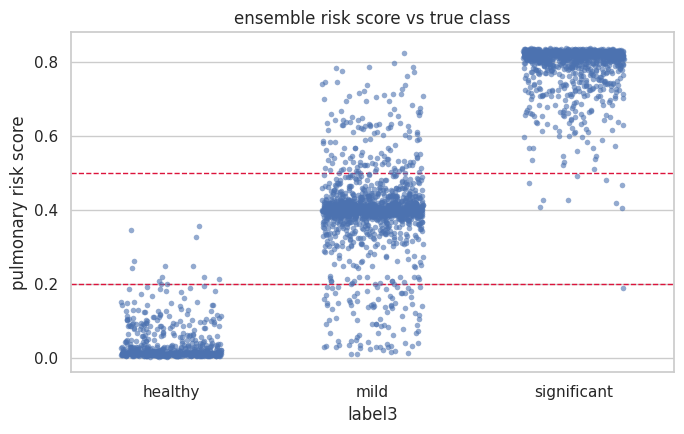

saved: predictions CSV + 5 fold models -> outputs_3class_ensemble


In [ ]:
# @title Risk scores + exports (every image, ensemble probabilities)
W = np.array([RISK_WEIGHTS[c] for c in CLASS_ORDER])

all_probs = ensemble_probs(df, fold_models, scaler)
df["pred3"] = [CLASS_ORDER[i] for i in all_probs.argmax(1)]
df["risk_score"] = (all_probs * W).sum(1)
df["risk_band"] = df["risk_score"].apply(
    lambda s: next((name for upper, name in RISK_BANDS if s < upper), "HIGH"))

print(df.groupby("label3")["risk_score"].mean().round(3).reindex(CLASS_ORDER))
plt.figure(figsize=(7, 4.5))
sns.stripplot(data=df, x="label3", y="risk_score", order=CLASS_ORDER, size=4,
              jitter=0.25, alpha=0.6)
for t in (0.20, 0.50):
    plt.axhline(t, ls="--", c="crimson", lw=1)
plt.ylabel("pulmonary risk score"); plt.title("ensemble risk score vs true class")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "ensemble_risk_scores.png", bbox_inches="tight")
plt.show()

export_cols = ["file", "split", "label", "label3", "pred3", "risk_score", "risk_band"] + \
              FEATURES + ["spine_detected"]
df[export_cols].to_csv(OUTPUT_DIR / "predictions_3class_ensemble.csv", index=False)

import os
os.makedirs(OUTPUT_DIR / "models", exist_ok=True)
for k, m in enumerate(fold_models, 1):
    torch.save({"state_dict": m.state_dict(), "classes": CLASS_ORDER, "backbone": BACKBONE,
                "img_size": IMG_SIZE, "features": FEATURES,
                "scaler_mean": scaler.mean_, "scaler_scale": scaler.scale_},
               OUTPUT_DIR / "models" / f"fold{k}.pt")
print(f"saved: predictions CSV + {len(fold_models)} fold models -> {OUTPUT_DIR}")

## Step 7 — Predict a new X-ray (committee of 5 + TTA)

In [ ]:
# @title Single-image ensemble prediction
def predict_xray_ensemble(path, show=True):
    """3-class + pulmonary risk for one image, via the full ensemble with TTA."""
    frame = pd.DataFrame([{"file": str(path), "spine_detected": 0,
                           **{k: 0.0 for k in FEATURES},
                           "crop_x0": np.nan, "crop_x1": np.nan,
                           "crop_y0": np.nan, "crop_y1": np.nan, "split": "new"}])
    try:
        f, _img, _mask, _ov = extract_features(path)
        if f is not None:
            frame.loc[0, "spine_detected"] = 1
            for k in FEATURES:
                frame.loc[0, k] = float(f[k])
            if _ov is not None and _ov[0] is not None:
                cl, _raw, bw = _ov
                m = 0.55 * bw
                span = cl[:, 1].max() - cl[:, 1].min()
                frame.loc[0, ["crop_x0", "crop_x1", "crop_y0", "crop_y1"]] = \
                    [max(cl[:, 0].min() - m, 0), cl[:, 0].max() + m + 1,
                     max(cl[:, 1].min() - 0.04 * span, 0), cl[:, 1].max() + 0.04 * span + 1]
    except Exception:
        pass

    P = np.zeros(len(CLASS_ORDER))
    for m in fold_models:
        P += predict_probs_tta_one(m, frame, scaler)[0]
    P /= len(fold_models)

    pred = CLASS_ORDER[int(P.argmax())]
    score = float((P * W).sum())
    band = next((name for upper, name in RISK_BANDS if score < upper), "HIGH")
    if show:
        show_overlay(path)
        plt.show()
    print(f"predicted class    : {pred}")
    print(f"pulmonary risk     : {score:.3f}  ({band})")
    print("class probabilities:", {c: round(float(p), 3) for c, p in zip(CLASS_ORDER, P)})
    return {"predicted_class": pred, "risk_score": round(score, 3), "risk_band": band,
            "probabilities": {c: round(float(p), 3) for c, p in zip(CLASS_ORDER, P)}}




In [ ]:
import pandas as pd
import numpy as np

In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded:", image_path)

result = predict_xray_ensemble("/content/" + image_path)

Saving N37-S-12-M_1_0_jpg.rf.c88169f244036d00c2361d33af0d1b48.jpg to N37-S-12-M_1_0_jpg.rf.c88169f244036d00c2361d33af0d1b48.jpg
Uploaded: N37-S-12-M_1_0_jpg.rf.c88169f244036d00c2361d33af0d1b48.jpg


NameError: name 'FEATURES' is not defined

In [ ]:
# @title Save everything to Drive (Colab)
import shutil, os
if os.path.isdir("/content/drive/MyDrive"):
    shutil.copytree(OUTPUT_DIR, f"/content/drive/MyDrive/{OUTPUT_DIR.name}", dirs_exist_ok=True)
    print(f"copied {OUTPUT_DIR}/ -> /content/drive/MyDrive/{OUTPUT_DIR.name}/")
else:
    print("Drive not mounted (or not on Colab) — outputs stay in", OUTPUT_DIR)

copied outputs_3class_ensemble/ -> /content/drive/MyDrive/outputs_3class_ensemble/


## How to read the results

* **Cross-validated accuracy** (Step 4) — the honest generalisation estimate; quote this.
* **3-class test accuracy** (Step 5) — the headline number on the untouched official test set.
* **Screening sens/spec** — the clinical triage numbers.
* **Risk plot/CSV** — per-image pulmonary-risk stratification for referral decisions.

If the test accuracy lands below the cross-validated estimate by a lot, the test
folder is distributed differently from train (worth checking). Small gaps are normal.

> Research screening aid — not a diagnostic device; validate against spirometry.